<a href="https://colab.research.google.com/github/DaviSchulz/Para-Minha-Pequena/blob/main/Trabalho_de_fundamentos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Trabalho Prático - Análise de Dados do ENEM 2023

Este notebook apresenta o desenvolvimento do trabalho prático de análise de dados e modelagem preditiva utilizando os microdados do ENEM 2023.

## 1. Configuração do Ambiente e Extração dos Dados

In [5]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


Nota de Reprodutibilidade (Item 2.1 do Enunciado)
Para reproduzir esta análise a partir de um ambiente limpo no Google Colab:
1. Faça o upload do arquivo oficial de microdados do INEP `microdados_enem_2023.zip` diretamente no diretório raiz `/content/`.
2. Execute as células sequencialmente. O script detectará o arquivo comprimido, efetuará a extração estruturada e lerá o arquivo CSV principal de forma otimizada via chunks.
3. O recorte filtrado resultante com 15.000 candidatos do Paraná (PR) pode ser exportado ao final se desejado.


In [6]:
import zipfile
import os

zip_path = '/content/microdados_enem_2023.zip'
extract_path = '/content/enem_2023_extracted'

try:
    if not os.path.exists(extract_path):
        print("A extrair o ficheiro...")
        with zipfile.ZipFile(zip_path, 'r') as zip_ref:
            zip_ref.extractall(extract_path)
        print("Extração concluída!")
    else:
        print("Os ficheiros já foram extraídos anteriormente.")
except Exception as e:
    print(f"Ocorreu um erro ao extrair: {e}")

csv_files = []
for root, dirs, files in os.walk(extract_path):
    for file in files:
        if file.lower().endswith('.csv'):
            full_path = os.path.join(root, file)
            csv_files.append(full_path)
            print(f"Ficheiro CSV encontrado: {full_path} ({os.path.getsize(full_path) / (1024*1024):.2f} MB)")

Os ficheiros já foram extraídos anteriormente.
Ficheiro CSV encontrado: /content/enem_2023_extracted/microdados_enem_2023/DADOS/MICRODADOS_ENEM_2023.csv (1694.83 MB)
Ficheiro CSV encontrado: /content/enem_2023_extracted/microdados_enem_2023/DADOS/ITENS_PROVA_2023.csv (0.32 MB)


## 2. Validação e Carregamento de Amostra dos Dados

Vamos carregar apenas as primeiras linhas para confirmar a estrutura e as colunas disponíveis antes de prosseguir.

Detalhe Metodológico: Variável `TP_FAIXA_ETARIA`
Conforme o dicionário de dados oficial do ENEM 2023, a coluna `TP_FAIXA_ETARIA` é uma escala ordinal codificada com valores inteiros de 1 a 20 (onde 1 representa menores de 17 anos e 20 representa 70 anos ou mais), não correspondendo à idade exata em anos. O modelo trata esta variável respeitando sua natureza numérica ordenada no pré-processamento.


In [7]:
import pandas as pd
import os

DATA_PATH = "/content/MICRODADOS_ENEM_2023.csv"

if not os.path.exists(DATA_PATH):
    for root, dirs, files in os.walk('/content'):
        for file in files:
            if file.lower().endswith('.csv') and 'microdados' in file.lower():
                DATA_PATH = os.path.join(root, file)
                break

print(f"A testar acesso ao ficheiro em: {DATA_PATH}")

amostra_cabecalho = pd.read_csv(DATA_PATH, sep=";", encoding="latin1", nrows=5, low_memory=False)
if amostra_cabecalho.shape[1] == 1:
    amostra_cabecalho = pd.read_csv(DATA_PATH, nrows=5, low_memory=False)

print("Total de colunas:", len(amostra_cabecalho.columns))
print("Nomes das colunas encontradas:")
print(amostra_cabecalho.columns.tolist())

print("\nVisualização das primeiras linhas:")
display(amostra_cabecalho.head())

A testar acesso ao ficheiro em: /content/enem_2023_extracted/microdados_enem_2023/DADOS/MICRODADOS_ENEM_2023.csv
Total de colunas: 76
Nomes das colunas encontradas:
['NU_INSCRICAO', 'NU_ANO', 'TP_FAIXA_ETARIA', 'TP_SEXO', 'TP_ESTADO_CIVIL', 'TP_COR_RACA', 'TP_NACIONALIDADE', 'TP_ST_CONCLUSAO', 'TP_ANO_CONCLUIU', 'TP_ESCOLA', 'TP_ENSINO', 'IN_TREINEIRO', 'CO_MUNICIPIO_ESC', 'NO_MUNICIPIO_ESC', 'CO_UF_ESC', 'SG_UF_ESC', 'TP_DEPENDENCIA_ADM_ESC', 'TP_LOCALIZACAO_ESC', 'TP_SIT_FUNC_ESC', 'CO_MUNICIPIO_PROVA', 'NO_MUNICIPIO_PROVA', 'CO_UF_PROVA', 'SG_UF_PROVA', 'TP_PRESENCA_CN', 'TP_PRESENCA_CH', 'TP_PRESENCA_LC', 'TP_PRESENCA_MT', 'CO_PROVA_CN', 'CO_PROVA_CH', 'CO_PROVA_LC', 'CO_PROVA_MT', 'NU_NOTA_CN', 'NU_NOTA_CH', 'NU_NOTA_LC', 'NU_NOTA_MT', 'TX_RESPOSTAS_CN', 'TX_RESPOSTAS_CH', 'TX_RESPOSTAS_LC', 'TX_RESPOSTAS_MT', 'TP_LINGUA', 'TX_GABARITO_CN', 'TX_GABARITO_CH', 'TX_GABARITO_LC', 'TX_GABARITO_MT', 'TP_STATUS_REDACAO', 'NU_NOTA_COMP1', 'NU_NOTA_COMP2', 'NU_NOTA_COMP3', 'NU_NOTA_COMP4',

,NU_INSCRICAO,NU_ANO,TP_FAIXA_ETARIA,TP_SEXO,TP_ESTADO_CIVIL,TP_COR_RACA,TP_NACIONALIDADE,TP_ST_CONCLUSAO,TP_ANO_CONCLUIU,TP_ESCOLA,...,Q016,Q017,Q018,Q019,Q020,Q021,Q022,Q023,Q024,Q025
0,210059085136,2023,14,M,2,1,1,1,17,1,...,C,C,B,B,A,B,B,A,A,B
1,210059527735,2023,12,M,2,1,0,1,16,1,...,B,A,B,B,A,A,C,A,D,B
2,210061103945,2023,6,F,1,1,1,1,0,1,...,B,A,A,B,A,A,A,A,A,B
3,210060214087,2023,2,F,1,3,1,2,0,2,...,A,A,A,B,A,A,D,A,A,B
4,210059980948,2023,3,F,1,3,1,2,0,2,...,A,A,A,B,A,A,B,A,A,A


Error: Runtime no longer has a reference to this dataframe, please re-run this cell and try again.


## 3. Pipeline de Modelação Preditiva de Ponta a Ponta

Nesta secção, estruturamos o pipeline unificado com semente fixa (`SEED = 42`) para garantir a reprodutibilidade dos resultados conforme o enunciado do trabalho prático.

Engenharia do Pipeline de Modelagem Preditiva
O fluxo de execução abaixo realiza os seguintes passos de ponta a ponta de forma limpa e sem vazamento de dados (*data leakage*):
- Carregamento Incremental: Leitura em blocos (*chunks*) limitando o uso de memória RAM.
- Definição da População de Estudo: Filtragem estrita de candidatos do PR que compareceram a ambos os dias e possuem notas válidas.
- Pré-processamento via ColumnTransformer: Tratamento de dados nulos nas variáveis socioeconômicas (`Q001` e `Q002`) pela mediana, acompanhado de indicadores de ausência; padronização de variáveis contínuas e codificação One-Hot robusta para variáveis categóricas.
- Modelagem e Avaliação: Treinamento de um Baseline ingênuo, três algoritmos clássicos (`Ridge`, `DecisionTree`, `KNN`) e uma Rede Neural (`MLP`) usando Validação Cruzada de 5-folds no conjunto de treino e avaliação final no conjunto de teste independente.

A carregar o ficheiro em: /content/enem_2023_extracted/microdados_enem_2023/DADOS/MICRODADOS_ENEM_2023.csv
A ler chunks e filtrando candidatos do Paraná (PR) em 2023...
População amostrada (PR, presentes, redação válida): 15000 linhas | 13 preditores

Estatísticas descritivas da NOTA_MEDIA:
count    15000.00
mean       554.84
std         85.82
min        191.86
25%        494.66
50%        551.08
75%        612.86
max        828.98
Name: NOTA_MEDIA, dtype: float64

% de valores ausentes nas features (antes da imputação):
Q001                      8.41
Q002                      2.61
TP_FAIXA_ETARIA           0.00
Q005                      0.00
Q006                      0.00
TP_SEXO                   0.00
TP_COR_RACA               0.00
TP_ST_CONCLUSAO           0.00
TP_ESCOLA                 0.00
TP_DEPENDENCIA_ADM_ESC    0.00
TP_LOCALIZACAO_ESC        0.00
Q003                      0.00
Q004                      0.00
dtype: float64


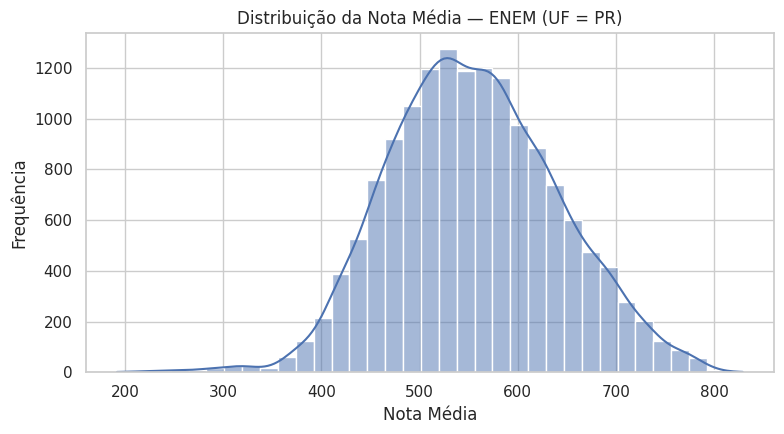

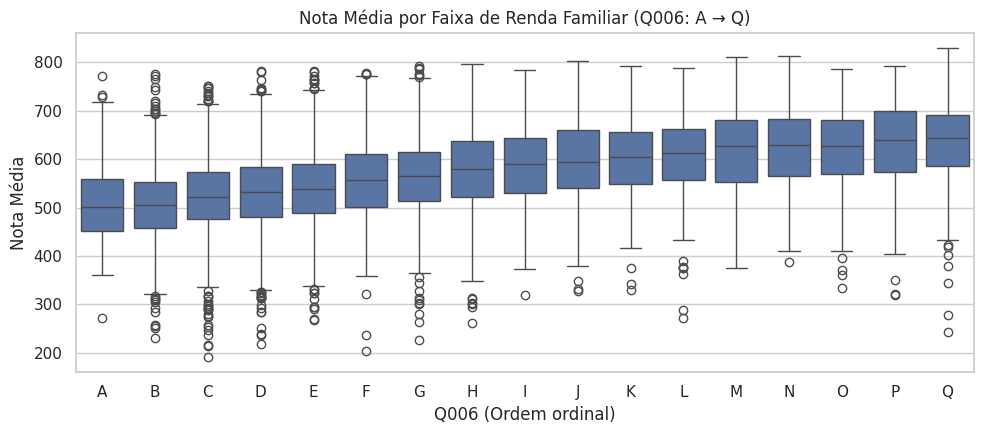


Comparação de modelos (seleção via CV no treino; teste avaliado ao final):
          Modelo  CV_MAE  CV_RMSE   CV_R2  Teste_MAE  Teste_RMSE  Teste_R2  Tempo_CV_s
             MLP 57.7962  72.8218  0.2741    59.3724     75.2690    0.2531       14.56
           Ridge 58.1738  73.3335  0.2637    59.2932     75.1679    0.2551        0.82
             KNN 59.3377  74.8755  0.2324    60.6299     76.6706    0.2250        1.47
    DecisionTree 59.5144  75.0257  0.2294    60.9983     77.0078    0.2182        0.85
Baseline (média) 68.6518  85.4926 -0.0004    70.0313     87.0933   -0.0000        3.03


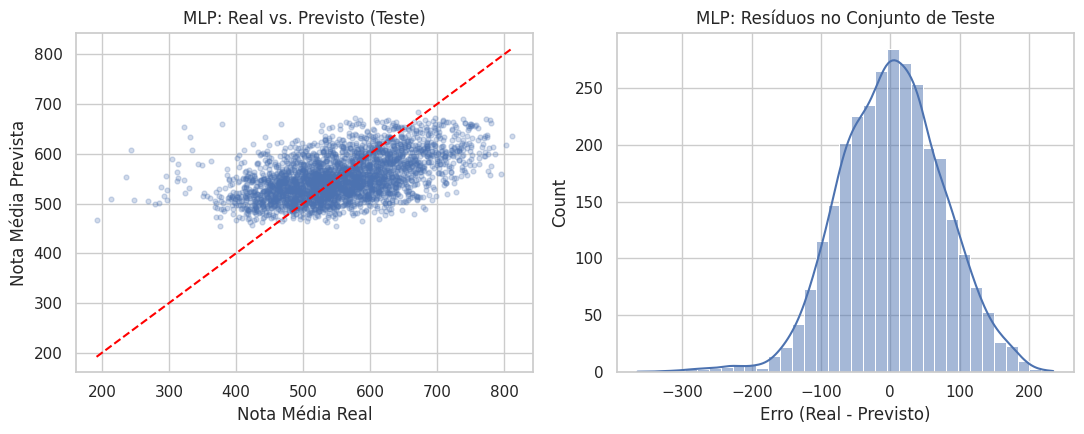

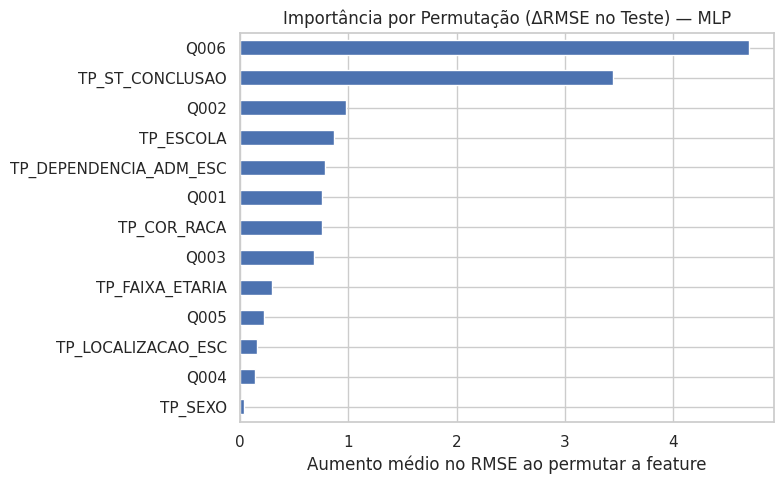

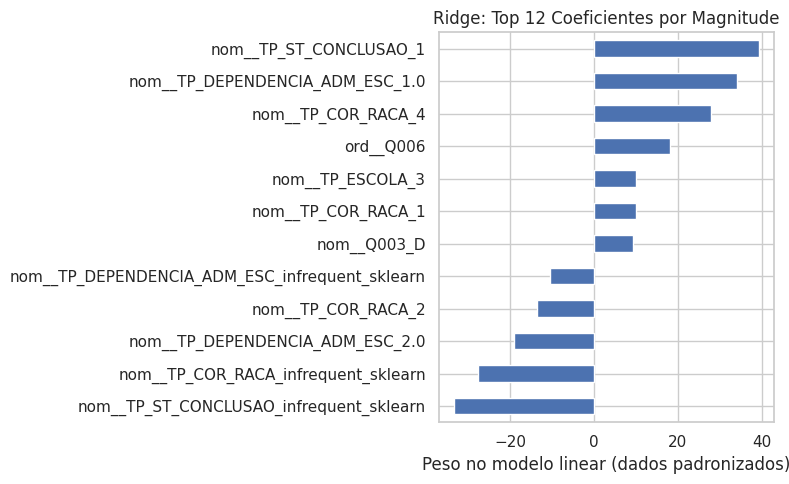

In [8]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

from sklearn.model_selection import train_test_split, KFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, StandardScaler
from sklearn.metrics import mean_absolute_error, root_mean_squared_error, r2_score
from sklearn.dummy import DummyRegressor
from sklearn.inspection import permutation_importance

from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.neighbors import KNeighborsRegressor
from sklearn.neural_network import MLPRegressor

SEED = 42
np.random.seed(SEED)
plt.rcParams["figure.figsize"] = (8, 4.5)
sns.set_theme(style="whitegrid")

DATA_PATH = "/content/MICRODADOS_ENEM_2023.csv"
N_AMOSTRA = 15000

# Fallback dinâmico de segurança caso não esteja na raiz
if not os.path.exists(DATA_PATH):
    for root, dirs, files in os.walk('/content'):
        for file in files:
            if file.lower().endswith('.csv') and 'microdados' in file.lower():
                DATA_PATH = os.path.join(root, file)
                break

NOTAS_COLS = [
    "NU_NOTA_CN", "NU_NOTA_CH", "NU_NOTA_LC", "NU_NOTA_MT", "NU_NOTA_REDACAO"
]
PRESENCA_COLS = [
    "TP_PRESENCA_CN", "TP_PRESENCA_CH", "TP_PRESENCA_LC", "TP_PRESENCA_MT"
]

NUM_COLS = ["TP_FAIXA_ETARIA", "Q005"]  # TP_FAIXA_ETARIA substitui NU_IDADE no ENEM 2023
ORD = {
    "Q001": list("ABCDEFG"),  # H = "Não sei" -> vira NaN e ganha indicador de ausência
    "Q002": list("ABCDEFG"),
    "Q006": list("ABCDEFGHIJKLMNOPQ"),
}
ORD_COLS = list(ORD.keys())
NOM_COLS = [
    "TP_SEXO", "TP_COR_RACA", "TP_ST_CONCLUSAO",
    "TP_ESCOLA", "TP_DEPENDENCIA_ADM_ESC", "TP_LOCALIZACAO_ESC",
    "Q003", "Q004"
]

USECOLS = list(dict.fromkeys(
    ["SG_UF_PROVA", "TP_STATUS_REDACAO"]
    + NOTAS_COLS + PRESENCA_COLS + NUM_COLS + ORD_COLS + NOM_COLS
))

print(f"A carregar o ficheiro em: {DATA_PATH}")
print("A ler chunks e filtrando candidatos do Paraná (PR) em 2023...")
chunks = pd.read_csv(
    DATA_PATH, sep=";", encoding="latin1",
    usecols=USECOLS, chunksize=200_000, low_memory=False
)
df = pd.concat(
    [c[c["SG_UF_PROVA"].astype(str).str.strip() == "PR"] for c in chunks],
    ignore_index=True
)

df = df[
    (df[PRESENCA_COLS] == 1).all(axis=1)
    & (df["TP_STATUS_REDACAO"] == 1)
].dropna(subset=NOTAS_COLS).copy()

df = df.sample(n=min(N_AMOSTRA, len(df)), random_state=SEED).reset_index(drop=True)
df["NOTA_MEDIA"] = df[NOTAS_COLS].mean(axis=1)

for col_ord in ["Q001", "Q002"]:
    if col_ord in df.columns:
        df[col_ord] = df[col_ord].replace({"H": np.nan})

df[NOM_COLS] = df[NOM_COLS].astype("string").fillna("AUSENTE").astype(object)

FEATURE_COLS = list(dict.fromkeys(NUM_COLS + ORD_COLS + NOM_COLS))
X = df[FEATURE_COLS].copy()
y = df["NOTA_MEDIA"].copy()

print(f"População amostrada (PR, presentes, redação válida): {len(X)} linhas | {X.shape[1]} preditores")

print("\nEstatísticas descritivas da NOTA_MEDIA:")
print(y.describe().round(2))

print("\n% de valores ausentes nas features (antes da imputação):")
print((X.isna().mean() * 100).round(2).sort_values(ascending=False))

fig, ax = plt.subplots()
sns.histplot(y, bins=35, kde=True, ax=ax)
ax.set_title("Distribuição da Nota Média — ENEM (UF = PR)")
ax.set_xlabel("Nota Média")
ax.set_ylabel("Frequência")
plt.tight_layout()
plt.show()

if "Q006" in df.columns:
    ordem_q006 = [k for k in ORD["Q006"] if k in set(df["Q006"].dropna())]
    fig, ax = plt.subplots(figsize=(10, 4.5))
    sns.boxplot(data=df, x="Q006", y="NOTA_MEDIA", order=ordem_q006, ax=ax)
    ax.set_title("Nota Média por Faixa de Renda Familiar (Q006: A → Q)")
    ax.set_xlabel("Q006 (Ordem ordinal)")
    ax.set_ylabel("Nota Média")
    plt.tight_layout()
    plt.show()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED
)

num_tf = Pipeline([
    ("imp", SimpleImputer(strategy="median", add_indicator=True)),
    ("sc", StandardScaler())
])

ord_tf = Pipeline([
    ("enc", OrdinalEncoder(
        categories=[ORD[c] for c in ORD_COLS],
        handle_unknown="use_encoded_value",
        unknown_value=np.nan
    )),
    ("imp", SimpleImputer(strategy="median", add_indicator=True)),
    ("sc", StandardScaler())
])

nom_tf = OneHotEncoder(handle_unknown="ignore", min_frequency=0.01, sparse_output=False)

preprocessor = ColumnTransformer([
    ("num", num_tf, NUM_COLS),
    ("ord", ord_tf, ORD_COLS),
    ("nom", nom_tf, NOM_COLS),
], remainder="drop")

modelos = {
    "Baseline (média)": DummyRegressor(strategy="mean"),
    "Ridge": Ridge(alpha=10.0, random_state=SEED),
    "DecisionTree": DecisionTreeRegressor(max_depth=6, min_samples_leaf=30, random_state=SEED),
    "KNN": KNeighborsRegressor(n_neighbors=15, n_jobs=-1),
    "MLP": MLPRegressor(
        hidden_layer_sizes=(64, 32), max_iter=300,
        early_stopping=True, random_state=SEED
    ),
}

cv = KFold(n_splits=5, shuffle=True, random_state=SEED)
scoring = {
    "mae": "neg_mean_absolute_error",
    "rmse": "neg_root_mean_squared_error",
    "r2": "r2",
}

resultados = []
pipelines_treinados = {}

for nome, est in modelos.items():
    pipe = Pipeline([
        ("prep", preprocessor),
        ("model", est)
    ])
    t0 = time.perf_counter()
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=-1)
    tempo_cv = time.perf_counter() - t0

    pipe.fit(X_train, y_train)
    y_pred_test = pipe.predict(X_test)
    pipelines_treinados[nome] = pipe

    resultados.append({
        "Modelo": nome,
        "CV_MAE": -scores["test_mae"].mean(),
        "CV_RMSE": -scores["test_rmse"].mean(),
        "CV_R2": scores["test_r2"].mean(),
        "Teste_MAE": mean_absolute_error(y_test, y_pred_test),
        "Teste_RMSE": root_mean_squared_error(y_test, y_pred_test),
        "Teste_R2": r2_score(y_test, y_pred_test),
        "Tempo_CV_s": round(tempo_cv, 2),
    })

df_res = pd.DataFrame(resultados).sort_values("CV_RMSE")
print("\nComparação de modelos (seleção via CV no treino; teste avaliado ao final):")
print(df_res.round(4).to_string(index=False))

candidatos = df_res[df_res["Modelo"] != "Baseline (média)"]
melhor_nome = candidatos.iloc[0]["Modelo"]
best_pipe = pipelines_treinados[melhor_nome]
y_pred_best = best_pipe.predict(X_test)
residuos = y_test - y_pred_best

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
axes[0].scatter(y_test, y_pred_best, alpha=0.25, s=12)
lims = [min(y_test.min(), y_pred_best.min()), max(y_test.max(), y_pred_best.max())]
axes[0].plot(lims, lims, "--", color="red")
axes[0].set_title(f"{melhor_nome}: Real vs. Previsto (Teste)")
axes[0].set_xlabel("Nota Média Real")
axes[0].set_ylabel("Nota Média Prevista")

sns.histplot(residuos, bins=35, kde=True, ax=axes[1])
axes[1].set_title(f"{melhor_nome}: Resíduos no Conjunto de Teste")
axes[1].set_xlabel("Erro (Real - Previsto)")
plt.tight_layout()
plt.show()

imp = permutation_importance(
    best_pipe, X_test, y_test,
    n_repeats=5, scoring="neg_root_mean_squared_error",
    random_state=SEED, n_jobs=-1
)
s_imp = pd.Series(imp.importances_mean, index=X_test.columns).sort_values()

fig, ax = plt.subplots(figsize=(8, 5))
s_imp.plot.barh(ax=ax)
ax.set_title(f"Importância por Permutação (ΔRMSE no Teste) — {melhor_nome}")
ax.set_xlabel("Aumento médio no RMSE ao permutar a feature")
plt.tight_layout()
plt.show()

if "Ridge" in pipelines_treinados:
    ridge_pipe = pipelines_treinados["Ridge"]
    feat_names = ridge_pipe.named_steps["prep"].get_feature_names_out()
    coefs = pd.Series(ridge_pipe.named_steps["model"].coef_, index=feat_names)
    top_coefs = coefs.reindex(coefs.abs().sort_values(ascending=False).head(12).index).sort_values()
    fig, ax = plt.subplots(figsize=(8, 5))
    top_coefs.plot.barh(ax=ax)
    ax.set_title("Ridge: Top 12 Coeficientes por Magnitude")
    ax.set_xlabel("Peso no modelo linear (dados padronizados)")
    plt.tight_layout()
    plt.show()